In [1]:
import numpy as np

import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split

dataset = np.load('dataset1.npz')
X_train = dataset['X_train']
X_test = dataset['X_test']


y_train = dataset['y_train']
y_test = dataset['y_test']

print(X_train.shape, X_test.shape)
print("train classes:", np.unique(y_train, return_counts=True))


print("test classes: ", np.unique(y_test, return_counts=True))

# (a) kNN with k=4
kNN = KNeighborsClassifier(n_neighbors=4)

kNN.fit(X_train, y_train)

print("accuracy (train):", accuracy_score(y_train, kNN.predict(X_train)))


print("accuracy (test): ", accuracy_score(y_test, kNN.predict(X_test)))

(400, 2) (100, 2)
train classes: (array([0, 1]), array([200, 200]))
test classes:  (array([0, 1]), array([50, 50]))
accuracy (train): 0.9125
accuracy (test):  0.89


best k: 7 validation accuracy: 0.925


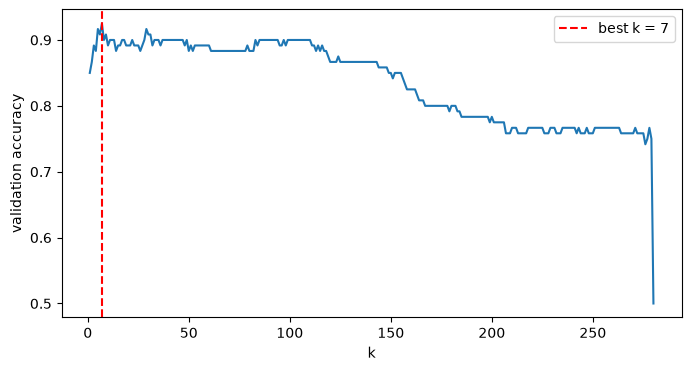

In [2]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.3, random_state=0, stratify=y_train)

ks = list(range(1, len(X_tr) + 1))      
val_acc = []
for k in ks:
    
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    
    val_acc.append(accuracy_score(y_val, knn.predict(X_val)))

best_k = ks[int(np.argmax(val_acc))]
print("best k:", best_k, "validation accuracy:", max(val_acc))

plt.figure(figsize=(8, 4))
plt.plot(ks, val_acc)


plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k')

plt.ylabel('validation accuracy')
plt.legend()



plt.show()

In [3]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)

final_knn.fit(X_train, y_train)

print("accuracy (train):", accuracy_score(y_train, final_knn.predict(X_train)))



print("accuracy (test): ", accuracy_score(y_test, final_knn.predict(X_test)))

accuracy (train): 0.915
accuracy (test):  0.91


## Adapt the code to train k-NN with k = 4 and report the train and test accuracy. What do you observe?


#### The training accuracy is 0.9125, while the test accuracy is 0.89. The classes are balanced so the baseline is 0.5 and the model is far above the baseline. as the model is fitted on the training set, the training accuracy is a little bit higher than the test accuracy. There is no strong overfitting as the gap is small.


## Find the best value for k. Split the training data into a train and validation set (30% validation). Plot the validation accuracy for all possible values of k, then train k-NN with the best k and report the test accuracy again. Which values for k did you choose? Did the test accuracy improve as expected?

#### I splitted the train data into 30% of validation set and computed the validation accuracy for every k between 1 and 280. For k=1 the accuracy is above 0.85 and k=7 achieves the best accuracy of 0.925 and it is at the peak.The accuracy remains around 0.89-0.9 up to k=120 and then starts dropping to around 0.77 because the neighborhood becomes too large (underfitting) and eventually, for k=280, it decreases to 0.5. Further, I chose k=7 for training and it resulted in test accuracy of 0.91 and train accuracy of 0.915.  

## Assume you want to train k-NN on another dataset. Can you use the same value of k? Why/ Why not?

#### No, the best k depends on several factors like the properties of the dataset, the amount of noise and class overlap and also the number of training samples. In the dataset provided here, the validation accuracy does not change notably for k between 10 and 120, so the specific choice matters little but in a different dataset it can have a much narrower optimum. Thus, k needs to be selected for validation data in every dataset 